<a href="https://colab.research.google.com/github/jbyiringiro/gdp-time-series-pipeline/blob/main/Building_a_Pipeline_for_Time_Series_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Time-series Preprocessing and Exploratory Analysis

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

pd.options.display.float_format = '{:,.2f}'.format

# Every figure is also saved as a PNG so it can be used in the PDF report
FIG_DIR = 'report/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

# Plot style: a fixed colour order for series (grey = baseline/context) and light solid gridlines
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#8a8a8a']
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e5e5e5',
    'grid.linewidth': 0.8,
    'lines.linewidth': 2,
})

## Problem Definition

**Problem statement:** Estimate the United States' **annual Gross Domestic Product (GDP)**, in current US dollars, for year *t* from the economy's recent history and two same-year indicators.

For each year *t* the model receives:
- **GDP history up to year *t*−1:** last year's GDP (`GDP_Lag1`) and the average GDP of the five previous years (`GDP_5Year_MA`);
- **two indicators for year *t*:** `Population` and `Final consumption expenditure`;

and outputs one number: GDP for year *t*. Because two of the inputs are values for the same year, this is a **nowcast** (an estimate of the current year's GDP from related figures) rather than a forecast several years ahead.

| Item | Definition |
|---|---|
| Unit of analysis | United States, one row per year |
| Target | `Gross Domestic Product (GDP)`, current US$ |
| Type of task | Regression on a time series, one year at a time |
| Training years | 1975–2011 (first 80% of usable years, in time order) |
| Test years | 2012–2021 (last 20%, includes the 2020 COVID-19 shock) |
| Metrics | RMSE (US$), MAPE (%), R² |
| Success criterion | Lower test error than the naive forecast "GDP this year = GDP last year" |

**Why this problem matters:** GDP is the main measure of the size of an economy. Governments plan budgets and set debt and deficit targets as a percentage of GDP, central banks use it to judge whether the economy is growing or shrinking, and businesses use it to size markets. The official annual figure is only published after the year ends and is revised later, so a transparent estimate built from figures that are already available is useful for planning. The US is the most consequential case to study because it is the world's largest economy (see *Why the United States* below).

**Why it is a time-series problem:** GDP in one year builds on GDP in the year before, so the order of the rows carries information. We therefore (1) build lagged and moving-average features, (2) split training and test data by time instead of at random, and (3) tune hyperparameters on time-ordered folds, so the model never learns from the future.

## Dataset and Justification

**Source:** *Global Economy Indicators* on Kaggle ([prasad22/global-economy-indicators](https://www.kaggle.com/datasets/prasad22/global-economy-indicators)), compiled from the **United Nations Statistics Division's National Accounts Main Aggregates Database**. That database is the product of a cooperation between the UN Statistics Division, international statistical agencies and the national statistical services of each country, and it follows one accounting standard (the UN System of National Accounts). The file has **10,512 rows** (one per country per year) covering **220 countries** from **1970 to 2021**, with **26 columns**: GDP, Gross National Income, population, exchange rates, the expenditure components of GDP (consumption, investment, exports, imports) and value added by economic sector.

**How it meets the assignment requirements:**

| Requirement | In this dataset |
|---|---|
| Clear timestamp/date column | `Year` (1970–2021), one record per country per year |
| Meaningful prediction target | `Gross Domestic Product (GDP)` |
| Multiple measurable variables over time | 22 numeric indicators recorded every year |

**Why we chose this dataset:**
1. **The predictors have a known link to the target.** GDP measured by expenditure is the sum of consumption, investment and net exports: GDP = C + I + (X − M). The dataset contains each of these parts, and for the US they add up to the reported GDP within 0.53% in every year (checked in Step 2 below). We therefore know *why* the predictors should work, instead of relying on whatever happens to correlate.
2. **One official source and one method.** All values come from the UN and follow the same accounting rules, so years and countries are comparable. This matters for a time series: a change in how data is collected would look like a change in the economy.
3. **Long enough to include shocks.** 52 years cover several business cycles, including the 2008–09 financial crisis and the 2020 pandemic, which caused the only two yearly falls in US GDP. Our test period (2012–2021) contains the 2020 shock, so the evaluation is not limited to calm years.
4. **Few gaps.** Only 0.87% of all values are missing, and 78% of those are in a single column (`Changes in inventories`) that we do not model. Little imputation is needed, so the results reflect the data and not our filling method.
5. **It fits the whole pipeline.** The country-by-year structure maps directly onto the relational schema in Task 2 (`countries`, `exchange_rates`, `economic_indicators`) and onto one MongoDB document per country-year, and yearly records are easy to serve by date range from the Task 3 API.

**Why the United States:**
- **Largest economy in the dataset:** US$23.3 trillion in 2021, 24% of the world total (31% in 1970), so changes in US GDP affect the rest of the world.
- **Complete series:** all 52 years are present and none of the columns we model has a missing value.
- **No currency distortion:** GDP is recorded in US dollars and the US exchange rate is 1.0 in every year. For other countries, GDP in dollars mixes real economic change with exchange-rate swings; for the US it does not.

**Limitations and how we deal with them:**

| Limitation | Effect | What we do |
|---|---|---|
| Annual data: 52 points for one country (47 after building features) | Little data to learn from; complex models overfit | Few features, simple models, small tuning grids, strict time-based split |
| Values are in current (nominal) dollars | Growth includes inflation, not only more output | We predict nominal GDP and say so; growth rates in the analysis are nominal |
| US values are rounded to 3 significant figures (e.g. US$1.07 trillion for 1970) | Changes smaller than about 0.5–1% are partly rounding | Differences in error below ~1% are not treated as meaningful |

## A. Understanding the Dataset

### Step 1: Load the data and clean the names

**What we did:** loaded the CSV from our GitHub repository and stripped the spaces around the column names and the text columns.

**Why:** in the raw file every header and text value is padded with spaces (`' Country '`, `' Afghanistan '`). Without stripping, `df['Country'] == 'United States'` matches nothing and column look-ups by name fail.

In [2]:
# Use the CSV in the repository; fall back to GitHub when it is not there (e.g. in Colab)
CSV_PATH = 'Global Economy Indicators.csv'
Url = "https://raw.githubusercontent.com/jbyiringiro/gdp-time-series-pipeline/refs/heads/main/Global%20Economy%20Indicators.csv"
df = pd.read_csv(CSV_PATH if os.path.exists(CSV_PATH) else Url)

# Column names and text values contain extra spaces (e.g. ' Country '), so we strip them
df.columns = df.columns.str.strip()
df['Country'] = df['Country'].str.strip()
df['Currency'] = df['Currency'].str.strip()

target = 'Gross Domestic Product (GDP)'
country_name = "United States"

print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Countries: {df['Country'].nunique()}")
print(df.dtypes.value_counts())

Rows: 10,512 | Columns: 26 | Countries: 220
float64    20
int64       4
object      2
Name: count, dtype: int64


The table has 26 columns: two identifiers (`CountryID`, `Country`), the time column `Year`, the text column `Currency`, and 22 numeric indicators.

### Step 2: Check the evidence behind our dataset choice

**What we did:** tested the claims made in *Dataset and Justification*: how large the US economy is, whether its series is complete, whether its exchange rate is constant, and whether consumption + investment + exports − imports really add up to GDP.

US share of world GDP: 31.4% in 1970, 24.3% in 2021
US years: 1970-2021 (52 years), missing values in the columns we model: 0
US exchange rate values: [1.]
C + I + X - M vs. GDP: largest difference in any year = 0.53% of GDP
Consumption as a share of GDP: 80.2% on average


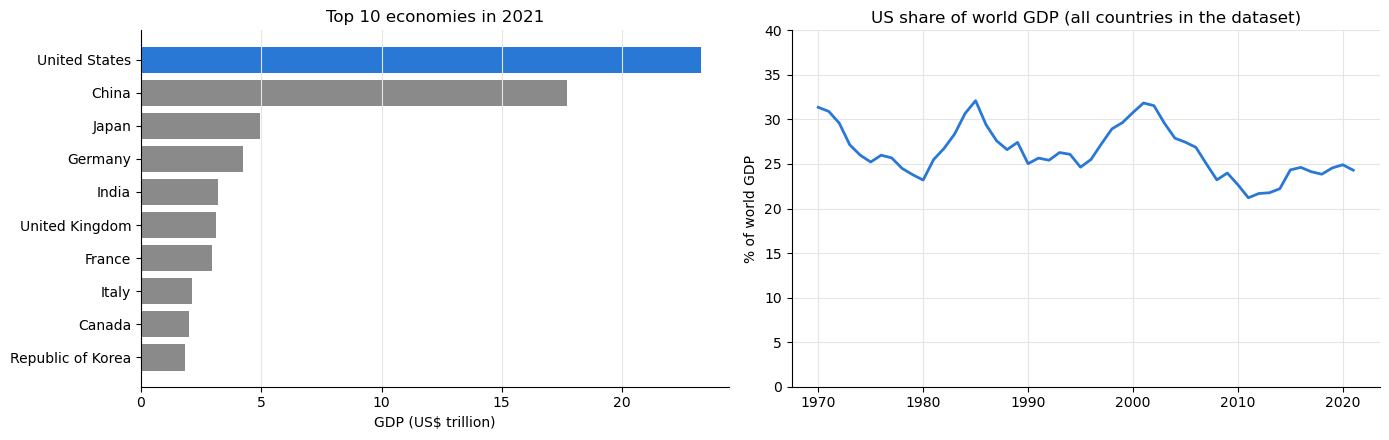

In [3]:
us = df[df['Country'] == country_name].set_index('Year')

# 1. Size: the largest economies in 2021 and the US share of the world total in the dataset
top10 = df[df['Year'] == 2021].nlargest(10, target).set_index('Country')[target] / 1e12
world_gdp = df.groupby('Year')[target].sum()
us_share = us[target] / world_gdp * 100
print(f"US share of world GDP: {us_share[1970]:.1f}% in 1970, {us_share[2021]:.1f}% in 2021")

# 2. Completeness and currency
model_cols = [target, 'Population', 'Final consumption expenditure']
print(f"US years: {us.index.min()}-{us.index.max()} ({len(us)} years), "
      f"missing values in the columns we model: {us[model_cols].isnull().sum().sum()}")
print(f"US exchange rate values: {us['AMA exchange rate'].unique()}")

# 3. GDP identity: consumption + investment + exports - imports should add up to GDP
components = (us['Final consumption expenditure'] + us['Gross capital formation']
              + us['Exports of goods and services'] - us['Imports of goods and services'])
identity_gap = (components / us[target] - 1) * 100
print(f"C + I + X - M vs. GDP: largest difference in any year = {identity_gap.abs().max():.2f}% of GDP")
print(f"Consumption as a share of GDP: {(us['Final consumption expenditure'] / us[target]).mean() * 100:.1f}% on average")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bar_colors = [COLORS[0] if name == country_name else COLORS[3] for name in top10.index[::-1]]
axes[0].barh(top10.index[::-1], top10.values[::-1], color=bar_colors)
axes[0].set_title('Top 10 economies in 2021')
axes[0].set_xlabel('GDP (US$ trillion)')
axes[0].grid(axis='y', visible=False)

axes[1].plot(us_share, color=COLORS[0])
axes[1].set_title('US share of world GDP (all countries in the dataset)')
axes[1].set_ylabel('% of world GDP')
axes[1].set_ylim(0, 40)

plt.tight_layout()
save_fig('fig01_why_united_states')
plt.show()

**Interpretation:**
- The US is the largest economy in the dataset (US$23.3 trillion in 2021, ahead of China at US$17.7 trillion) and has produced between about a fifth and a third of world GDP (21–32%) in every year since 1970. Its GDP matters far beyond the US. The share moves up and down mainly because other countries' GDP is converted into dollars, so it changes with the value of the dollar.
- All 52 years are present and none of the columns we model has a gap.
- The exchange rate is 1.0 in every year, so US GDP in dollars moves only with the US economy, not with currency swings.
- Consumption + investment + exports − imports matches the reported GDP to within 0.53% in every year, and consumption alone is about 80% of GDP. The predictors have a direct, known relationship with the target.

### Step 3: Time range and frequency

**What we did:** checked the first and last year, the gap between consecutive records of each country, duplicate country-year rows, and how many countries report in each year.

**Why:** lag and moving-average features assume that one row equals one year. If some years were skipped or duplicated, `shift(1)` would not mean "the previous year".

Time range: 1970 to 2021 (52 years)
Gaps between consecutive records (years): [np.float64(1.0)]
Duplicate (Country, Year) rows: 0
Countries with all 52 years: 179 of 220
In 1990 but not in 1991: ['Czechoslovakia (Former)', 'USSR (Former)', 'Yemen Arab Republic (Former)', 'Yemen Democratic (Former)', 'Yugoslavia (Former)']


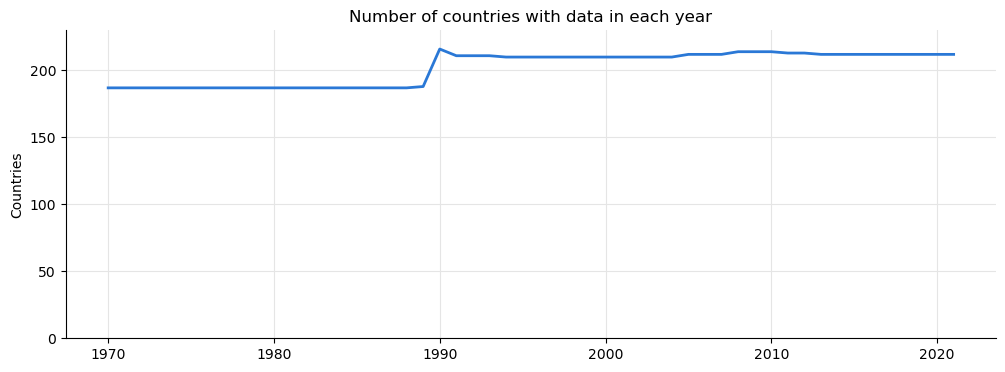

In [4]:
print(f"Time range: {df['Year'].min()} to {df['Year'].max()} ({df['Year'].nunique()} years)")

# Frequency: the gap between consecutive records of the same country
year_steps = df.sort_values(['Country', 'Year']).groupby('Country')['Year'].diff().dropna()
print(f"Gaps between consecutive records (years): {sorted(year_steps.unique())}")
print(f"Duplicate (Country, Year) rows: {df.duplicated(['Country', 'Year']).sum()}")

years_per_country = df.groupby('Country')['Year'].count()
print(f"Countries with all 52 years: {(years_per_country == 52).sum()} of {len(years_per_country)}")
print("In 1990 but not in 1991:", sorted(set(df[df['Year'] == 1990]['Country']) - set(df[df['Year'] == 1991]['Country'])))

countries_per_year = df.groupby('Year')['Country'].nunique()
plt.figure(figsize=(12, 4))
plt.plot(countries_per_year, color=COLORS[0])
plt.title('Number of countries with data in each year')
plt.ylabel('Countries')
plt.ylim(0, 230)
save_fig('fig02_countries_per_year')
plt.show()

**Interpretation:**
- **Time range:** 1970 to 2021, 52 years.
- **Frequency/granularity:** annual. Every gap between consecutive records is exactly one year and there are no duplicate country-year rows, so no resampling is needed and `shift(1)` always means "the previous year".
- **Coverage:** 179 of the 220 countries have all 52 years. The count jumps from 187 to 216 in 1990, when the successor states of the USSR, Yugoslavia and Czechoslovakia first appear, and drops to 211 in 1991, when the former states (and the two former Yemens) end. In 1990 the former states and their successors are both present, so any world total for 1990 counts those economies twice (which slightly lowers the US share for that year in Step 2). It does not affect the US series we model, but anyone summing across countries should exclude one of the two groups for 1990.

### Step 4: Missing values

**What we did:** measured missing values for every column in the full dataset, then for the US series, and filled the US gaps.

Missing values in the full dataset: 2,374 (0.87% of all cells)


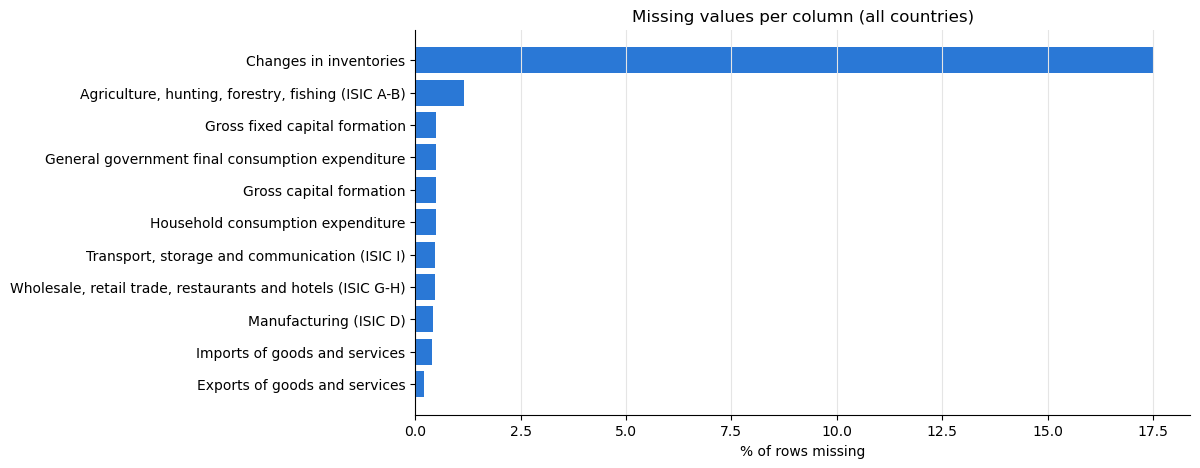

Missing values in the US series: 2
      Changes in inventories
Year                        
1970                     NaN
1971                     NaN
Missing values after handling: 0


In [5]:
total_missing = df.isnull().sum().sum()
print(f"Missing values in the full dataset: {total_missing:,} ({total_missing / df.size * 100:.2f}% of all cells)")

missing_pct = (df.isnull().mean() * 100).sort_values()
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 5))
plt.barh(missing_pct.index.str.replace(r'\s*\(including.*\)', '', regex=True), missing_pct.values, color=COLORS[0])
plt.title('Missing values per column (all countries)')
plt.xlabel('% of rows missing')
plt.grid(axis='y', visible=False)
save_fig('fig03_missing_values')
plt.show()

# Select a specific country for time-series analysis
ts_data = df[df['Country'] == country_name].sort_values('Year').set_index('Year')

# Log missing values before handling
missing_pre = ts_data.isnull().sum()
print(f"Missing values in the US series: {missing_pre.sum()}")
print(ts_data.loc[ts_data.isnull().any(axis=1), missing_pre[missing_pre > 0].index])

# Linear interpolation fills gaps between known years; ffill/bfill handle gaps at the start or end.
# Only numeric columns are interpolated (text columns like Country cannot be)
numeric_cols = ts_data.select_dtypes('number').columns
ts_data[numeric_cols] = ts_data[numeric_cols].interpolate(method='linear').ffill().bfill()
print(f"Missing values after handling: {ts_data[numeric_cols].isnull().sum().sum()}")

**What we found:** 2,374 values (0.87% of all cells) are missing in the full dataset, and 78% of them are in one column, `Changes in inventories` (17.5% of its rows are empty). Every other column is at least 98.8% complete. The US series has only **2 missing values**, both in `Changes in inventories`, for 1970 and 1971.

**How we handled them, and why this method:**
1. **Linear interpolation for gaps between two known years.** Economic indicators change gradually from one year to the next, so a straight line between the neighbouring years keeps the trend. Filling with the column mean would be wrong for a trending series: the mean US GDP (US$9.3 trillion) is almost nine times the 1970 value, so a mean-filled 1970s value would be a huge spike. Filling with zero would be worse.
2. **Back-fill / forward-fill for gaps at the edges.** Interpolation needs a known value on both sides, so it cannot fill the first years of a series. The two US gaps are exactly this case (1970 and 1971 are the first two years), so they take the 1972 value.
3. **Why not drop the rows?** Dropping 1970 and 1971 would also delete GDP, population and consumption for those years, even though those columns are complete, and would shorten an already short series. Lag and moving-average features also need an unbroken run of years.

`Changes in inventories` is not a model input, so the filled values do not affect the model; filling them keeps the cleaning step valid for any column or country it is applied to.

### Step 5: Statistical distribution of numerical columns

**What we did:** summary statistics, skewness and histograms for the target and the main external variables.

Summary Statistics


,Gross Domestic Product (GDP),Population,Final consumption expenditure,Per capita GNI
count,52.00,52.00,52.00,52.00
mean,"9,321,346,153,846.15","268,076,552.38","7,604,865,384,615.38","32,119.44"
std,"6,499,368,002,109.72","43,251,698.86","5,418,868,607,147.01","18,944.10"
min,"1,070,000,000,000.00","200,328,340.00","840,000,000,000.00","5,363.00"
25%,"3,557,500,000,000.00","229,792,827.50","2,817,500,000,000.00","15,462.00"
50%,"7,855,000,000,000.00","267,322,451.50","6,260,000,000,000.00","29,212.50"
75%,"14,575,000,000,000.00","306,399,191.25","12,325,000,000,000.00","48,082.25"
max,"23,300,000,000,000.00","336,997,624.00","19,300,000,000,000.00","70,081.00"


Skewness:
Gross Domestic Product (GDP)    0.48
Population                      0.05
Final consumption expenditure   0.48
Per capita GNI                  0.28
dtype: float64


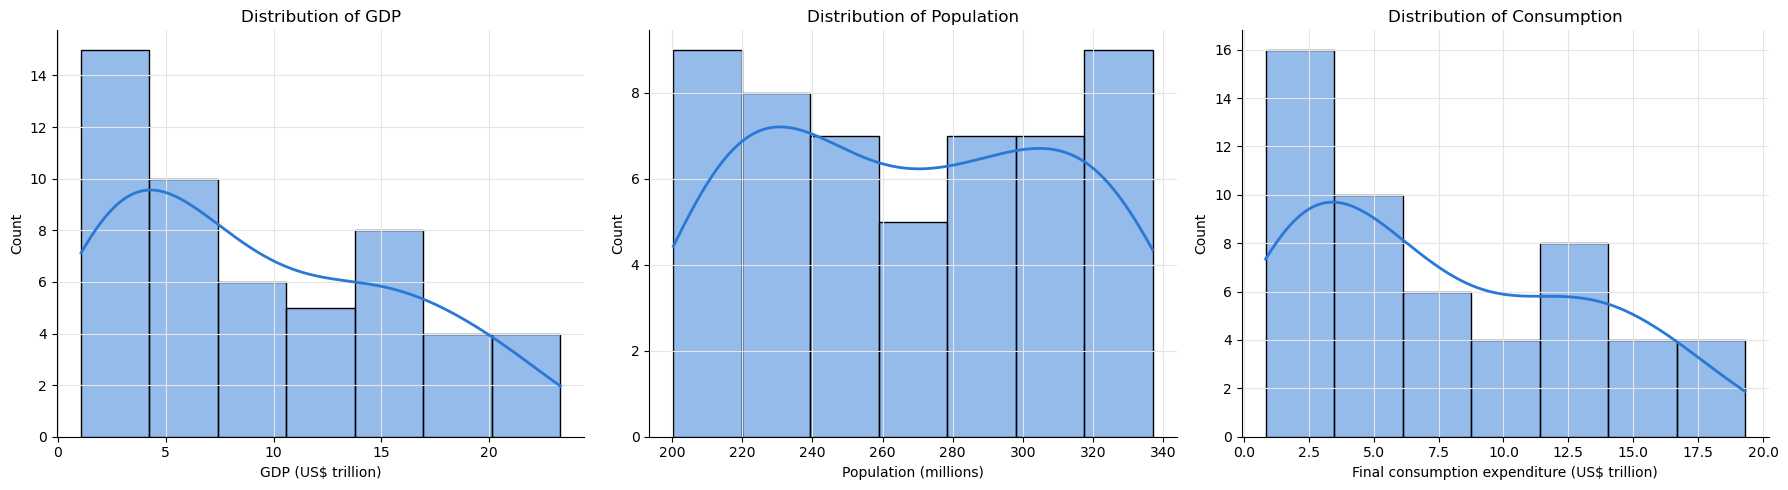

In [6]:
# 1. Display Summary Statistics
dist_cols = [target, 'Population', 'Final consumption expenditure', 'Per capita GNI']
print("Summary Statistics")
display(ts_data[dist_cols].describe())
print("Skewness:")
print(ts_data[dist_cols].skew().round(2))

# 2. Visualise Statistical Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(ts_data[target] / 1e12, kde=True, color=COLORS[0], ax=axes[0])
axes[0].set_title('Distribution of GDP')
axes[0].set_xlabel('GDP (US$ trillion)')

sns.histplot(ts_data['Population'] / 1e6, kde=True, color=COLORS[0], ax=axes[1])
axes[1].set_title('Distribution of Population')
axes[1].set_xlabel('Population (millions)')

sns.histplot(ts_data['Final consumption expenditure'] / 1e12, kde=True, color=COLORS[0], ax=axes[2])
axes[2].set_title('Distribution of Consumption')
axes[2].set_xlabel('Final consumption expenditure (US$ trillion)')

plt.tight_layout()
save_fig('fig04_distributions')
plt.show()

**Interpretation:**
- **GDP:** mean US$9.32 trillion, median US$7.86 trillion, standard deviation US$6.50 trillion, range US$1.07–23.3 trillion. The mean is above the median and the skew is 0.48: the distribution is right-skewed.
- **Consumption** has the same shape (skew 0.48), because it is a stable ~80% share of GDP.
- **Population** is almost symmetric (skew 0.05, 200 to 337 million): it grows by a similar number of people every year, so the years are spread evenly over its range.
- **Per capita GNI** ranges from US$5,363 to US$70,081 with a mild right skew (0.28).

**Why this matters:** for a time series, these histograms describe *when* values occurred rather than random variation. GDP grows by a percentage each year, so it spends many years at low values and only a few at high values, which produces the right skew. The mean and spread of GDP therefore depend on which years you look at. We test this formally next, because it decides which models can work.

### Step 6: Stationarity

**What we did:** ran the Augmented Dickey-Fuller (ADF) test on GDP and on its yearly growth rate. The test's null hypothesis is that the series is non-stationary (its mean and variance change over time); a p-value below 0.05 rejects that.

In [7]:
gdp_growth = ts_data[target].pct_change() * 100

for name, series in [('GDP level', ts_data[target]), ('GDP yearly growth (%)', gdp_growth.dropna())]:
    p_value = adfuller(series, autolag='AIC')[1]
    print(f"{name:<22} ADF p-value = {p_value:.3f} -> {'stationary' if p_value < 0.05 else 'non-stationary'}")

GDP level              ADF p-value = 0.997 -> non-stationary
GDP yearly growth (%)  ADF p-value = 0.211 -> non-stationary


**Interpretation:** the GDP level is clearly non-stationary (p = 0.997): it has a strong trend. Even the growth rate does not pass (p = 0.211), because nominal growth was much higher in the high-inflation 1970s (10.5% a year on average in 1971–1981) than after 2000 (around 4%).

**What this means for the rest of the work:**
1. The test years will contain GDP values higher than any in the training years, so the model must be able to **extrapolate**. This favours linear models over tree-based ones (confirmed in Part C).
2. Two trending series always look correlated, so in Q3 and Q4 we check correlations on **growth rates** as well as levels.
3. Features should describe the **recent history** of the series (lags and moving averages), so the model works relative to the current level of GDP.

## Time-Series Feature Engineering

To fulfil the requirement of utilising lagged features and moving averages, we engineered these variables before the analysis:
1. **GDP_Lag1 (lagged feature):** GDP shifted down by one year, so the row for year *t* holds GDP of year *t*−1. It lets the model ask: "Given last year's GDP, what will GDP be this year?" We use lag 1 because Q3 shows it is the most informative lag.
2. **GDP_5Year_MA (moving average):** the average GDP of the **five previous years** (*t*−5 to *t*−1). We apply `shift(1)` *before* `rolling(5)`. Without it, the average for year *t* would include year *t*'s GDP, the value we are trying to predict, and the model would be shown part of the answer (data leakage). Five years is long enough to smooth out a single bad year and short enough to keep 47 of the 52 years for modelling.
3. **GDP_Growth:** year-on-year change in %, used in the analysis because it removes the trend.

In [8]:
# Lagged feature: last year's GDP
ts_data['GDP_Lag1'] = ts_data[target].shift(1)

# Moving average of the 5 previous years. shift(1) comes first so that year t
# only averages years t-5 to t-1 and never includes the GDP we want to predict
ts_data['GDP_5Year_MA'] = ts_data[target].shift(1).rolling(window=5).mean()

# Year-on-year growth in %, used in the analytical questions
ts_data['GDP_Growth'] = gdp_growth

# Note: We do not drop NaNs just yet so we can visualize the full timeline in EDA
ts_data[[target, 'GDP_Lag1', 'GDP_5Year_MA', 'GDP_Growth']].head(7)

,Gross Domestic Product (GDP),GDP_Lag1,GDP_5Year_MA,GDP_Growth
Year,,,,
1970,"1,070,000,000,000.00",NaN,NaN,NaN
1971,"1,160,000,000,000.00","1,070,000,000,000.00",NaN,8.41
1972,"1,280,000,000,000.00","1,160,000,000,000.00",NaN,10.34
1973,"1,430,000,000,000.00","1,280,000,000,000.00",NaN,11.72
1974,"1,550,000,000,000.00","1,430,000,000,000.00",NaN,8.39
1975,"1,680,000,000,000.00","1,550,000,000,000.00","1,298,000,000,000.00",8.39
1976,"1,870,000,000,000.00","1,680,000,000,000.00","1,420,000,000,000.00",11.31


The first rows show how the features are built: 1970 has no previous year, so `GDP_Lag1` and `GDP_Growth` are empty, and `GDP_5Year_MA` needs five earlier years, so it starts in 1975. These rows are only dropped right before modelling, which is why the model uses 47 years (1975–2021).